# Malli 3 - Hienosäädetty (VGG16)

In [3]:
import keras
import matplotlib.pyplot as plt
import numpy as np
from keras import layers
from keras import models
from keras.models import Sequential
from keras.utils import image_dataset_from_directory
from scripts.notebook_scripts import collect_images, plot_images

Tämä notebookti tutkii hienosäädettyä VGG16-mallia käyttäen samaa kuvadataa kuin edellisissä note bookeissa.

Tämän kokeen tarkoituksena on verrata mallin tuloksia edellisiin kahteen malliin ja selvittää, paraneeko vai heikkeneekö yleistyskyky.

## Valmistelut

Ensin lataamme tietomme omiin hakemistoihinsa ja määrittelemme niille:
- kuvan koon (224 x 224)
- eräkoko
- tunnisteet

Nyt data on jaettu oikein ja valmis käytettäväksi!

In [4]:
batch_size = 32
img_size = (224, 224) # every image is 224x224 pixels

train_dataset = image_dataset_from_directory(
    "dataset/train",
    image_size=img_size,
    batch_size=batch_size,
    label_mode="categorical"
 )

validation_dataset = image_dataset_from_directory(
    "dataset/validation",
    image_size=img_size,
    batch_size=batch_size,
    label_mode="categorical"
 )

test_dataset = image_dataset_from_directory(
    "dataset/test",
    image_size=img_size,
    batch_size=batch_size,
    label_mode="categorical"
 )

num_classes = len(train_dataset.class_names)

Found 175 files belonging to 5 classes.
Found 40 files belonging to 5 classes.
Found 35 files belonging to 5 classes.


Luomme VGG16:n konvoluutiopohjan, joka koostuu kaikista konvoluutio- ja maksimikasauskerroksista ilman lopullisia täysin yhdistettyjä (dense) luokittelukerroksia.

Aluksi asetamme ``trainable`` = ``False`` jäädyttääksemme alaosan kerrokset, jolloin niiden parametrit eivät päivity koulutuksen aikana. Takaisinsironnassa häviöfunktion gradienteista kulkevat edelleen kerrosten läpi, mutta niiden painot eivät päivity.

In [5]:
conv_base = keras.applications.vgg16.VGG16(
    weights="imagenet",
    include_top=False)
conv_base.trainable = False

conv_base.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, None, None, 3)       │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_conv1 (Conv2D)                │ (None, None, None, 64)      │           1,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_conv2 (Conv2D)                │ (None, None, None, 64)      │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block1_pool (MaxPooling2D)           │ (None, None, None, 64)      │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_conv1 (Conv2D)                │ (None, None, None, 128)     │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_conv2 (Conv2D)                │ (None, None, None, 128)     │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block2_pool (MaxPooling2D)           │ (None, None, None, 128)     │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv1 (Conv2D)                │ (None, None, None, 256)     │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv2 (Conv2D)                │ (None, None, None, 256)     │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_conv3 (Conv2D)                │ (None, None, None, 256)     │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block3_pool (MaxPooling2D)           │ (None, None, None, 256)     │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv1 (Conv2D)                │ (None, None, None, 512)     │       1,180,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv2 (Conv2D)                │ (None, None, None, 512)     │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_conv3 (Conv2D)                │ (None, None, None, 512)     │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block4_pool (MaxPooling2D)           │ (None, None, None, 512)     │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv1 (Conv2D)                │ (None, None, None, 512)     │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv2 (Conv2D)                │ (None, None, None, 512)     │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_conv3 (Conv2D)                │ (None, None, None, 512)     │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ block5_pool (MaxPooling2D)           │ (None, None, None, 512)     │               0 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 14,714,688 (56.13 MB)

## Datan augmentointi

Tässä osassa käytämme samaa datan augmentointilogiikkaa kuin ensimmäisessä CNN-luokittelijassamme, jotta vertailu tulosten välillä on johdonmukaisempi.

In [6]:
data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),    # Randomly flip images horizontally
        layers.RandomRotation(0.2),         # Randomly rotate images by up to 20%
        layers.RandomZoom(0.2),             # Randomly zoom images by up to 20%
        layers.RandomTranslation(0.1, 0.1), # Randomly translate images by up to 10% in both directions
        layers.RandomBrightness(0.2),       # Randomly adjust brightness by up to 20%
        layers.RandomContrast(0.2),         # Randomly adjust contrast by up to 20%
    ]
)

## Jäädytetty malli

Tässä vaiheessa rakennamme mukautetun luokittelijan esikoulutetun VGG16-konvoluutiopohjan päälle.

**Yleiskatsaus:**

1. Kuvat augmentoidaan yleistyvyyden parantamiseksi.
2. VGG16-esikäsittely sovelletaan.
3. Data kulkee konvoluutiopohjan läpi tunnistaakseen korkean tason piirteet.
4. Flatten muuntaa datan 1D-vektoriksi.
5. Tiheä kerros, jossa on `x` yksikköä, oppii datasetsidonnaisia kuvioita.
6. Dropoutia käytetään ylioppimisen vähentämiseen.
7. Lopulliset todennäköisyydet lasketaan ``softmax``-toiminnolla.

Tässä koulutamme vain ylimmät kerrokset, kun taas perusmalli pysyy jäädytettynä.

In [7]:
inputs = keras.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)
x = keras.applications.vgg16.preprocess_input(x)
x = conv_base(x)
x = layers.Flatten()(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.4)(x)

outputs = layers.Dense(num_classes, activation="softmax")(x)

In [8]:
model = keras.Model(inputs, outputs)

## Koulutus

Malli käännetään (compiled) käyttäen:
- kategorista ristientropiaa häviöfunktiona
- RMSpropia optimoijana
- tarkkuutta (accuracy) arviointimittana

In [9]:
opt = keras.optimizers.RMSprop()
model.compile(loss="categorical_crossentropy",
              optimizer=opt,
              metrics=["accuracy"])

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)    │ (None, 224, 224, 3)       │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ sequential (Sequential)       │ (None, 224, 224, 3)       │               0 │ input_layer_1[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ get_item (GetItem)            │ (None, 224, 224)          │               0 │ sequential[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ get_item_1 (GetItem)          │ (None, 224, 224)          │               0 │ sequential[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ get_item_2 (GetItem)          │ (None, 224, 224)          │               0 │ sequential[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ stack (Stack)                 │ (None, 224, 224, 3)       │               0 │ get_item[0][0],            │
│                               │                           │                 │ get_item_1[0][0],          │
│                               │                           │                 │ get_item_2[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add (Add)                     │ (None, 224, 224, 3)       │               0 │ stack[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ vgg16 (Functional)            │ (None, 7, 7, 512)         │      14,714,688 │ add[0][0]                  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ flatten (Flatten)             │ (None, 25088)             │               0 │ vgg16[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense (Dense)                 │ (None, 128)               │       3,211,392 │ flatten[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout (Dropout)             │ (None, 128)               │               0 │ dense[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_1 (Dense)               │ (None, 5)                 │             645 │ dropout[0][0]              │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 17,926,725 (68.39 MB)

 Trainable params: 3,212,037 (12.25 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

Lisäämme ``ModelCheckpoint`` ja ``EarlyStopping`` takaisinkutsut koulutuksen aikana.

- ModelCheckpoint luo erillisen tarkistuspisteen, johon se tallentaa painot tietyin väliajoin. Siitä malli ja painot voidaan ladata jatkamaan koulutusta tallennetusta tilasta.

- EarlyStopping valvoo ennalta määriteltyä metriikkaa koulutuksen aikana ja pysäyttää prosessin, jos parannusta ei tapahdu useiden epochien ajan, mikä on määritetty `patience`-parametrillä.

In [10]:
callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="feature_extraction_with_data_augmentation.keras",
        save_best_only=True,
        monitor="val_loss"
    ),
    keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True)
]

In [11]:
history = model.fit(
    train_dataset,
    epochs=30,
    validation_data=validation_dataset,
    callbacks=callbacks
)

Epoch 1/30


C:\Users\taifj\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


6/6 ━━━━━━━━━━━━━━━━━━━━ 26s 4s/step - accuracy: 0.4857 - loss: 25.1026 - val_accuracy: 0.9250 - val_loss: 0.8104
Epoch 2/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 22s 4s/step - accuracy: 0.8857 - loss: 1.9057 - val_accuracy: 0.9000 - val_loss: 0.8047
Epoch 3/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 23s 4s/step - accuracy: 0.8914 - loss: 1.7012 - val_accuracy: 0.9750 - val_loss: 0.0874
Epoch 4/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 21s 3s/step - accuracy: 0.9314 - loss: 1.2888 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 5/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 20s 3s/step - accuracy: 0.9543 - loss: 0.6581 - val_accuracy: 1.0000 - val_loss: 0.0062
Epoch 6/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 21s 4s/step - accuracy: 0.9714 - loss: 0.7803 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 7/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 20s 3s/step - accuracy: 0.9829 - loss: 0.1306 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 8/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 20s 3s/step - accuracy: 0.9600 - loss: 0.6958 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Ep

## Visualisointi

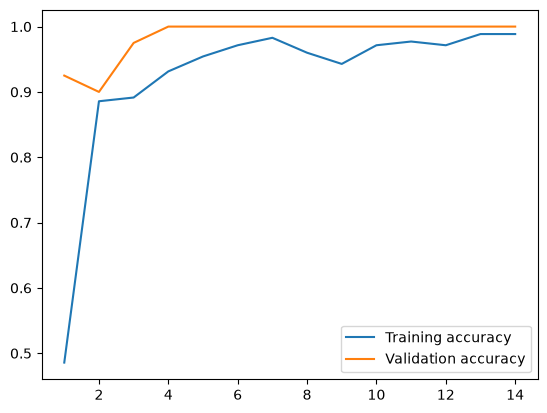

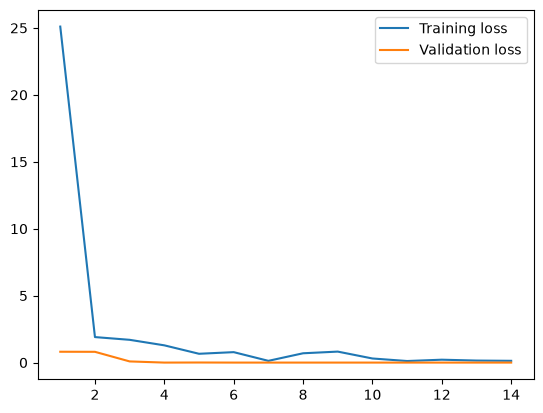

In [12]:
accuracy = history.history["accuracy"]
val_accuracy = history.history["val_accuracy"]
loss = history.history["loss"]
val_loss = history.history["val_loss"]
epochs = list(range(1, len(accuracy)+1))
plt.plot(epochs, accuracy, label="Training accuracy")
plt.plot(epochs, val_accuracy, label="Validation accuracy")
plt.legend()
plt.figure()
plt.plot(epochs, loss, label="Training loss")
plt.plot(epochs, val_loss, label="Validation loss")
plt.legend()
plt.show()

In [13]:
test_model = keras.models.load_model(
    "feature_extraction_with_data_augmentation.keras")
test_loss, test_acc = test_model.evaluate(test_dataset)
print(f"Test accuracy: {test_acc:3f}")

2/2 ━━━━━━━━━━━━━━━━━━━━ 5s 696ms/step - accuracy: 0.9429 - loss: 0.7420
Test accuracy: 0.942857


# Hienosäätö
Hienosäätö-vaiheessa esikoulutetun VGG16-mallin yläkerrokset avataan ja koulutetaan uudelleen käyttäen omaa tietojoukkoa.

Alemmat kerrokset jäävät jäädytetyiksi, koska ne sisältävät jo yleisiä visuaalisia piirteitä, kuten reunat ja tekstuurit.

Hienosäätö mahdollistaa mallin sopeutumisen korkeampitasoisiin piirteisiin erityisesti kohdeluokille, parantaen luokittelutulosta.

In [14]:
conv_base.trainable = True
for layer in conv_base.layers[:-4]:
    layer.trainable = False

In [15]:
finetuned_opt = keras.optimizers.RMSprop(learning_rate=1e-5)

model.compile(loss="categorical_crossentropy",
              optimizer=finetuned_opt,
              metrics=["accuracy"])

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)    │ (None, 224, 224, 3)       │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ sequential (Sequential)       │ (None, 224, 224, 3)       │               0 │ input_layer_1[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ get_item (GetItem)            │ (None, 224, 224)          │               0 │ sequential[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ get_item_1 (GetItem)          │ (None, 224, 224)          │               0 │ sequential[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ get_item_2 (GetItem)          │ (None, 224, 224)          │               0 │ sequential[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ stack (Stack)                 │ (None, 224, 224, 3)       │               0 │ get_item[0][0],            │
│                               │                           │                 │ get_item_1[0][0],          │
│                               │                           │                 │ get_item_2[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add (Add)                     │ (None, 224, 224, 3)       │               0 │ stack[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ vgg16 (Functional)            │ (None, 7, 7, 512)         │      14,714,688 │ add[0][0]                  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ flatten (Flatten)             │ (None, 25088)             │               0 │ vgg16[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense (Dense)                 │ (None, 128)               │       3,211,392 │ flatten[0][0]              │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout (Dropout)             │ (None, 128)               │               0 │ dense[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_1 (Dense)               │ (None, 5)                 │             645 │ dropout[0][0]              │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 17,926,725 (68.39 MB)

 Trainable params: 10,291,461 (39.26 MB)

 Non-trainable params: 7,635,264 (29.13 MB)

In [16]:
callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="fine_tuning.keras",
        save_best_only=True,
        monitor="val_loss"),
    keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=10,
        restore_best_weights=True)
]

In [17]:
history = model.fit(
    train_dataset,
    epochs=30,
    validation_data=validation_dataset,
    callbacks=callbacks)

Epoch 1/30
5/6 ━━━━━━━━━━━━━━━━━━━━ 3s 4s/step - accuracy: 0.9625 - loss: 0.5077WARNING:tensorflow:5 out of the last 113 calls to <function Trainer._make_function.<locals>.one_step_on_data at 0x000002B78324C720> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.9657 - loss: 0.4642WARNING:tensorflow:6 out of the last 114 calls to <function Trainer._make_function.<locals>.one_step_on_data at 0x000002B7834C5C70> triggered tf.functio

In [18]:
test_model = keras.models.load_model("fine_tuning.keras")
test_loss, test_acc = test_model.evaluate(test_dataset)
print(f"Test accuracy: {test_acc:3f}")

2/2 ━━━━━━━━━━━━━━━━━━━━ 4s 699ms/step - accuracy: 0.9429 - loss: 0.4347
Test accuracy: 0.942857


Hienosäätö paransi testitarkkuutta **90 %**:sta **95 %**:iin, mikä osoittaa, että yläpuolisten konvoluutiokerrosten antaminen mukautua omaan tietojoukkoon paransi mallin kykyä yleistää näkymättömiä kuvia.

In [19]:
num = len(test_dataset.file_paths)
print(f"\nNumber of pictures in test_dataset: {num}")
print(f"Ratio of predictions: {np.rint(num * test_acc)} : {np.rint(num - (num * test_acc))}")


Number of pictures in test_dataset: 35
Ratio of predictions: 33.0 : 2.0


## Ennusteiden analyysi

Jotta voimme analysoida mallin suorituskykyä tarkemmin, visualisoimme esimerkkejä:

- **Oikein luokitelluista kuvista**
- **Väärin luokitelluista kuvista**

Tämä auttaa ymmärtämään, missä malli toimii hyvin ja missä se kamppailee.

Tutkimalla väärin luokiteltuja kuvia voimme tunnistaa mahdollisia virheiden syitä, kuten:
- samanlaisia esineitä
- epätavallisia valaistusolosuhteita
- vaikeita kuvakulmia
- taustan häiriötekijöitä

Tämä tyyppinen laadullinen analyysi on tärkeä ymmärtääksemme mallin käyttäytymistä pelkkien tarkkuuslukujen lisäksi.

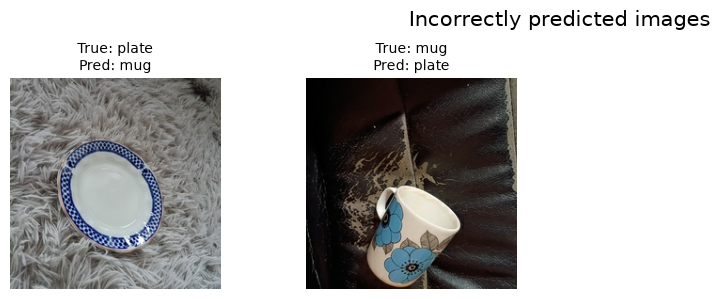

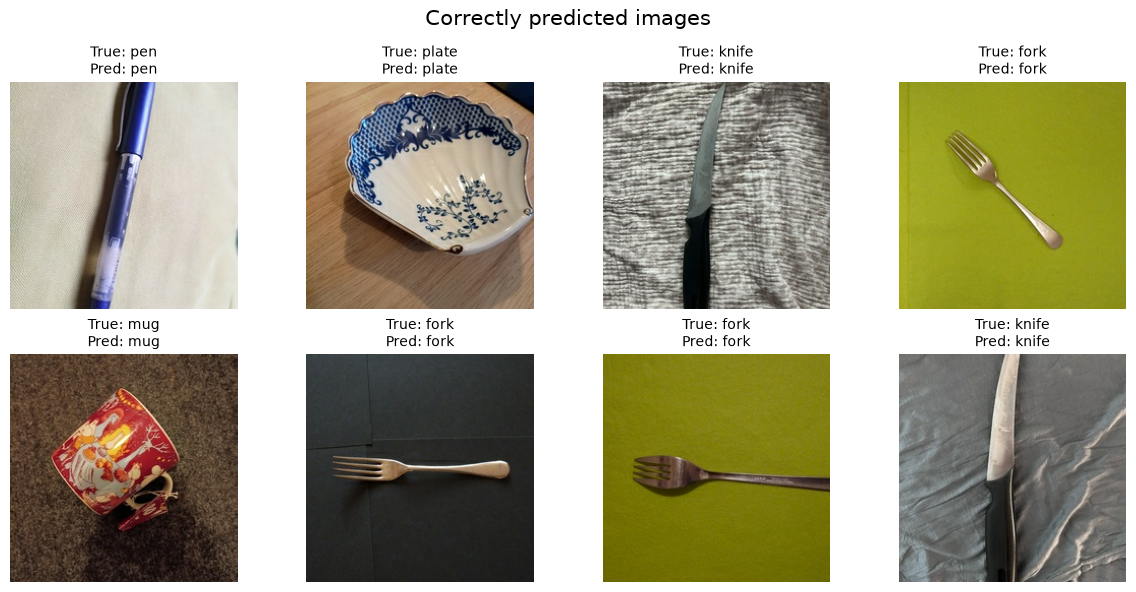

In [20]:
correct_images, wrong_images = collect_images(test_dataset, model)

plot_images(wrong_images, "Incorrectly predicted images")
plot_images(correct_images, "Correctly predicted images")

## Yhteenveto

Hienosäädetty VGG16-malli saavutti **95 %** testitarkkuuden, mikä vastaa **38 oikein luokiteltua kuvaa 40:stä**.

Hienosäätö mahdollisti esikoulutetun mallin mukautumisen tarkemmin omaan objektitietojoukkoon, parantaen kestävyyttä ja vähentäen virheellisiä luokitteluja.

Aiempiin malleihin verrattuna:

| Malli | Menetelmä | Testitarkkuus |
|---|---|---:|
| Malli 1 | Mukautettu CNN | 70 % |
| Malli 2 | Esikoulutettu VGG16 | 95 % |
| Malli 3 | Hienosäädetty VGG16 | 95 % |

Tulokset osoittavat, että siirto-oppiminen parantaa merkittävästi suorituskykyä verrattuna CNN:n kouluttamiseen alusta loppuun.

Vaikka lopullinen testitarkkuus pysyi samana kuin Malli 2:lla (95 %), hienosäädetty malli saavutti tämän tuloksen joustavammalla oppimisprosessilla.

Tämä viittaa siihen, että esikoulutetut VGG16-ominaisuudet olivat jo erittäin sopivia tehtävään, ja hienosäätö auttoi lähinnä parantamaan kestävyyttä eikä merkittävästi lisännyt raaka tarkkuutta.

Tämä on odotettavaa, koska tietojoukko on suhteellisen pieni ja objektit ovat visuaalisesti selvästi erottuvia.